# Análise de Inventário de Computadores

Este notebook analisa a planilha `relatorio.xlsx`, contendo o inventário de
equipamentos (desktops e notebooks) da empresa, para responder às seguintes
perguntas:

1. Quantos equipamentos são **PC (desktop)** e quantos são **NB (notebook)**?
2. Qual **departamento** tem a **menor média de memória RAM** por equipamento?
3. Qual o **total de máquinas sem antivírus** e quantas por **departamento**?
4. Quais **departamentos** têm mais máquinas com cada tipo de **processador**
   (Pentium R, Celeron R, i3, i5, i7)?

O notebook faz o tratamento dos dados (padronização de texto, conversão de
memória para valor numérico e extração da família do processador) antes de
responder cada pergunta, sempre acompanhado do gráfico correspondente.


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

#configurações visuais
plt.rcParams['figure.dpi'] = 100
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 150)

## 1. Carregamento dos dados

In [8]:
df = pd.read_excel('data/relatorio.xlsx')
df.head()

,Item,local,processador,memoria,HD,fabricante,mon_auxiliar,SO,office,tipo,anti_virus
0,PC-10,adm consorcio,i3-12,8gb,239gb,lenovo,lenovo,win 11 pro,WPS,PC,sim
1,PC-13,adm consorcio,i3-12,8gb,239gb,lenovo,VX pro,win 11 pro,WPS,PC,sim
2,PC-12,adm consorcio,i3-12,8gb,239gb,lenovo,samsung,win 11 pro,WPS,PC,sim
3,PC-11,adm consorcio,i3-12,8gb,239gb,lenovo,AOC,win 10 pro,WPS,PC,sim
4,PC-93,caixa oficina,pentium R,4gb,224gb,lenovo,LG,win 10 pro,libre,PC,sim


## 2. Tratamento e limpeza dos dados

Antes de responder as perguntas, é preciso:

- Verificar valores nulos e duplicados;
- Padronizar textos (remover espaços extras e uniformizar caixa) nas colunas
  categóricas (`tipo`, `local`, `anti_virus`);
- Converter a coluna `memoria` (texto, ex.: `"8gb"`) para um valor numérico
  em GB;
- Extrair a **família do processador** (Pentium R, Celeron R, i3, i5, i7) a
  partir da coluna `processador`, que traz o modelo específico
  (ex.: `"i5-11"`, `"I3-11"`, `"pentium R"`).

In [27]:
print('Valores nulos por coluna:')
print(df.isnull().sum())

Valores nulos por coluna:
Item            0
local           0
processador     0
memoria         0
HD              0
fabricante      0
mon_auxiliar    0
SO              0
office          0
tipo            0
anti_virus      0
dtype: int64


In [10]:
# Cópia de trabalho para não alterar o dataframe original
df_clean = df.copy()

# Padronização de colunas de texto: remove espaços nas pontas e uniformiza caixa
for col in ['tipo', 'local', 'anti_virus']:
    df_clean[col] = df_clean[col].astype(str).str.strip()

df_clean['tipo'] = df_clean['tipo'].str.upper()
df_clean['anti_virus'] = df_clean['anti_virus'].str.lower()
df_clean['local'] = df_clean['local'].str.strip()

# Conversão da memória de texto ("8gb") para número inteiro em GB
df_clean['memoria_gb'] = (
    df_clean['memoria']
    .astype(str)
    .str.strip()
    .str.lower()
    .str.replace('gb', '', regex=False)
    .astype(int)
)

print('Tipos únicos (tipo):', df_clean['tipo'].unique())
print('Valores únicos (anti_virus):', df_clean['anti_virus'].unique())
print('Memória em GB (valores únicos):', sorted(df_clean['memoria_gb'].unique()))

Tipos únicos (tipo): ['PC' 'NB']
Valores únicos (anti_virus): ['sim' 'nao']
Memória em GB (valores únicos): [np.int64(4), np.int64(6), np.int64(8), np.int64(12), np.int64(16), np.int64(24)]


In [11]:
# Extração da família do processador a partir da coluna 'processador'
def familia_processador(valor):
    p = str(valor).strip().lower()
    if p.startswith('pentium'):
        return 'Pentium R'
    if p.startswith('celeron'):
        return 'Celeron R'
    if p.startswith('i3'):
        return 'i3'
    if p.startswith('i5'):
        return 'i5'
    if p.startswith('i7'):
        return 'i7'
    return 'Outro'

df_clean['processador_familia'] = df_clean['processador'].apply(familia_processador)

print('Famílias de processador encontradas:')
print(df_clean['processador_familia'].value_counts())

Famílias de processador encontradas:
processador_familia
i3           89
i5           34
Pentium R    21
Celeron R     8
i7            1
Name: count, dtype: int64


In [12]:
df_clean.head()

,Item,local,processador,memoria,HD,fabricante,mon_auxiliar,SO,office,tipo,anti_virus,memoria_gb,processador_familia
0,PC-10,adm consorcio,i3-12,8gb,239gb,lenovo,lenovo,win 11 pro,WPS,PC,sim,8,i3
1,PC-13,adm consorcio,i3-12,8gb,239gb,lenovo,VX pro,win 11 pro,WPS,PC,sim,8,i3
2,PC-12,adm consorcio,i3-12,8gb,239gb,lenovo,samsung,win 11 pro,WPS,PC,sim,8,i3
3,PC-11,adm consorcio,i3-12,8gb,239gb,lenovo,AOC,win 10 pro,WPS,PC,sim,8,i3
4,PC-93,caixa oficina,pentium R,4gb,224gb,lenovo,LG,win 10 pro,libre,PC,sim,4,Pentium R


## 3. Pergunta 1 — Quantos equipamentos são PC (desktop) e quantos são NB (notebook)?

tipo
NB    100
PC     53
Name: count, dtype: int64


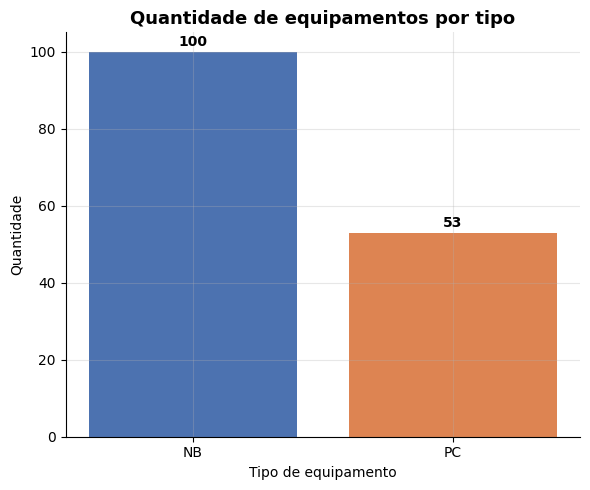

In [13]:
contagem_tipo = df_clean['tipo'].value_counts()
print(contagem_tipo)

fig, ax = plt.subplots(figsize=(6, 5))
cores = ['#4C72B0', '#DD8452']
barras = ax.bar(contagem_tipo.index, contagem_tipo.values, color=cores)

ax.set_title('Quantidade de equipamentos por tipo', fontsize=13, fontweight='bold')
ax.set_xlabel('Tipo de equipamento')
ax.set_ylabel('Quantidade')
ax.set_xticks(range(len(contagem_tipo)))
ax.set_xticklabels(['PC (Desktop)', 'NB (Notebook)'] if list(contagem_tipo.index) == ['PC', 'NB']
                    else contagem_tipo.index)

for barra in barras:
    altura = barra.get_height()
    ax.annotate(f'{int(altura)}', xy=(barra.get_x() + barra.get_width() / 2, altura),
                xytext=(0, 4), textcoords='offset points', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

Também é útil ver como esses equipamentos se distribuem **por
departamento** — quantos PCs e quantos NBs cada área possui.

In [14]:
# Quantidade de PC e NB em cada departamento
tabela_tipo_departamento = (
    pd.crosstab(df_clean['local'], df_clean['tipo'])
    .reindex(columns=['PC', 'NB'], fill_value=0)
)
# Ordena os departamentos pelo total de equipamentos (do maior para o menor)
tabela_tipo_departamento = tabela_tipo_departamento.loc[
    tabela_tipo_departamento.sum(axis=1).sort_values(ascending=False).index
]
tabela_tipo_departamento

tipo,PC,NB
local,,
telepecas,10,5
novos,0,14
financeiro,0,13
seminovos,3,8
consorcio,3,7
oficina,2,8
contabilidade,0,10
RH,0,6
seguros,1,5


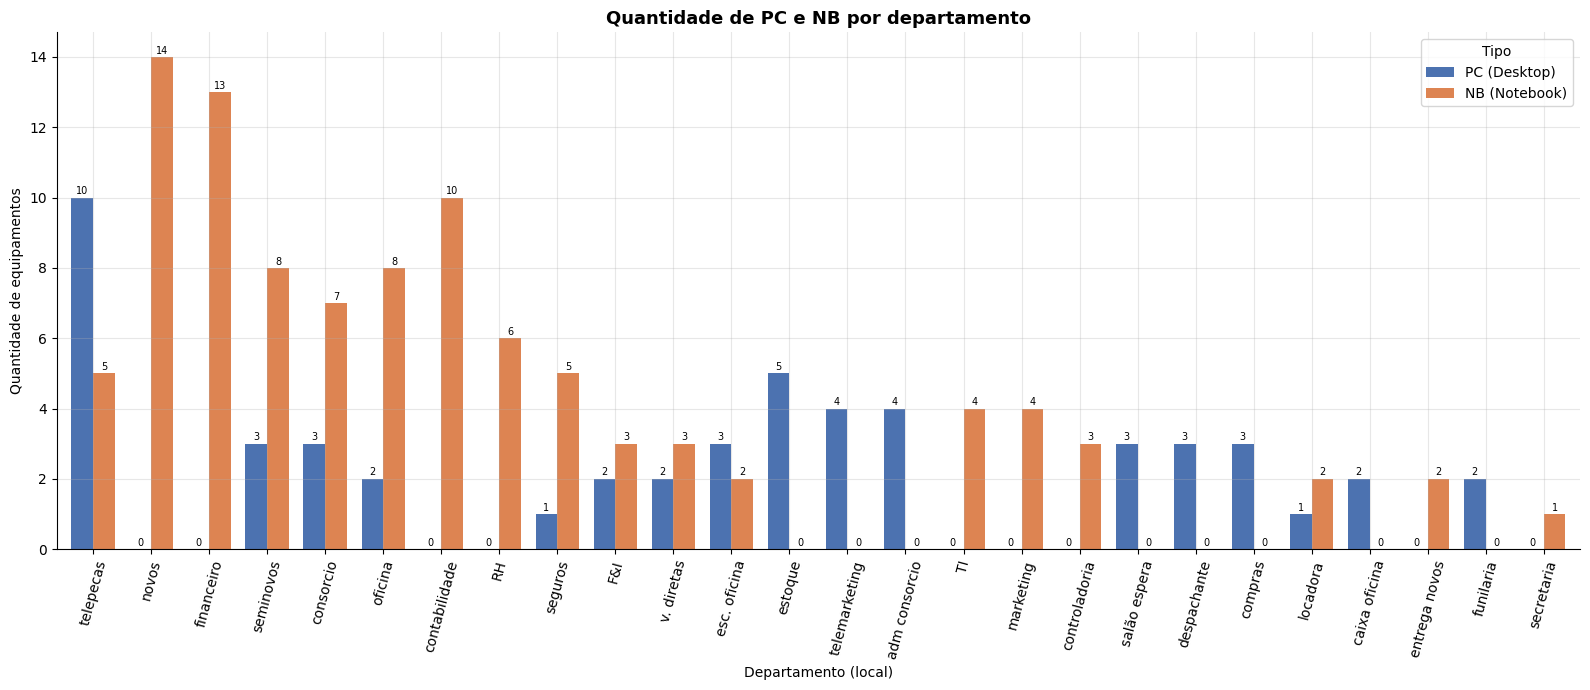

In [15]:
fig, ax = plt.subplots(figsize=(16, 7))
tabela_tipo_departamento.plot(kind='bar', ax=ax, color=cores, width=0.75)

ax.set_title('Quantidade de PC e NB por departamento', fontsize=13, fontweight='bold')
ax.set_xlabel('Departamento (local)')
ax.set_ylabel('Quantidade de equipamentos')
ax.legend(title='Tipo', labels=['PC (Desktop)', 'NB (Notebook)'])
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))

for container in ax.containers:
    ax.bar_label(container, fontsize=7, padding=1)

plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

**Resposta:** o gráfico e a contagem no início desta seção mostram o total
geral de equipamentos do tipo PC (desktop) e NB (notebook) no inventário; o
gráfico de barras agrupadas logo acima detalha essa mesma contagem
**por departamento**.

## 4. Pergunta 2 — Qual departamento tem menos memória RAM por equipamento?

Como cada departamento (`local`) possui uma quantidade diferente de
equipamentos, a comparação mais justa é pela **média de memória RAM por
equipamento** em cada departamento (e não pela soma total).

In [16]:
ram_departamento = (
    df_clean.groupby('local')['memoria_gb']
    .agg(media_ram='mean', qtd_equipamentos='count')
    .sort_values('media_ram')
)

print(ram_departamento.round(2))

# Cuidado com empates: pode haver mais de um departamento com a MESMA menor média
valor_menor_ram = ram_departamento['media_ram'].min()
deptos_menor_ram = ram_departamento[ram_departamento['media_ram'] == valor_menor_ram].index.tolist()

if len(deptos_menor_ram) == 1:
    print(f"\nDepartamento com menor média de RAM por equipamento: "
          f"'{deptos_menor_ram[0]}' ({valor_menor_ram:.2f} GB em média)")
else:
    lista = ', '.join(f"'{d}'" for d in deptos_menor_ram)
    print(f"\nHá um empate: {len(deptos_menor_ram)} departamentos com a menor média de "
          f"RAM por equipamento ({valor_menor_ram:.2f} GB em média): {lista}")

               media_ram  qtd_equipamentos
local                                     
caixa oficina       4.00                 2
despachante         4.00                 3
esc. oficina        4.80                 5
estoque             5.20                 5
seguros             5.33                 6
seminovos           5.82                11
contabilidade       6.40                10
controladoria       6.67                 3
consorcio           6.80                10
v. diretas          6.80                 5
novos               7.14                14
oficina             7.20                10
F&I                 7.20                 5
financeiro          7.38                13
telepecas           7.47                15
telemarketing       7.50                 4
secretaria          8.00                 1
adm consorcio       8.00                 4
entrega novos       8.00                 2
funilaria           8.00                 2
RH                  8.00                 6
salão esper

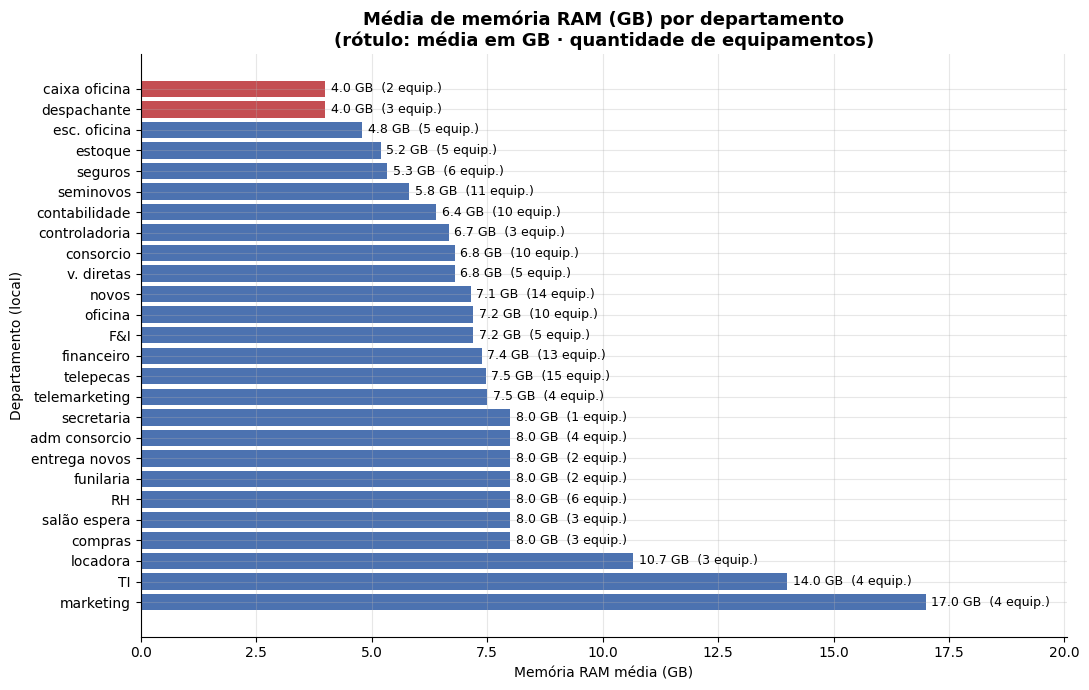

In [17]:
fig, ax = plt.subplots(figsize=(11, 7))
cores_ram = ['#C44E52' if depto in deptos_menor_ram else '#4C72B0'
             for depto in ram_departamento.index]

ax.barh(ram_departamento.index, ram_departamento['media_ram'], color=cores_ram)
ax.set_title('Média de memória RAM (GB) por departamento\n(rótulo: média em GB · quantidade de equipamentos)',
              fontsize=13, fontweight='bold')
ax.set_xlabel('Memória RAM média (GB)')
ax.set_ylabel('Departamento (local)')
ax.invert_yaxis()  # menor valor no topo
ax.set_xlim(0, ram_departamento['media_ram'].max() * 1.18)

for i, (valor, qtd) in enumerate(zip(ram_departamento['media_ram'], ram_departamento['qtd_equipamentos'])):
    ax.annotate(f'{valor:.1f} GB  ({int(qtd)} equip.)', xy=(valor, i), xytext=(4, 0),
                textcoords='offset points', va='center', fontsize=9)

plt.tight_layout()
plt.show()

**Resposta:** o(s) departamento(s) em destaque (vermelho) no gráfico acima
é(são) o(s) que possui(em) a menor média de memória RAM por equipamento. Cada
barra traz, além da média em GB, a quantidade de equipamentos (n) daquele
departamento entre parênteses — importante para avaliar o quanto essa média
é representativa (departamentos com poucos equipamentos, como n=1, pesam
menos como referência do que departamentos com muitos equipamentos).

## 5. Pergunta 3 — Total de máquinas sem antivírus (e por departamento)

In [18]:
total_sem_av = (df_clean['anti_virus'] == 'nao').sum()
total_maquinas = len(df_clean)
print(f'Total de máquinas sem antivírus: {total_sem_av} de {total_maquinas} '
      f'({total_sem_av/total_maquinas:.1%})')

Total de máquinas sem antivírus: 30 de 153 (19.6%)


In [19]:
sem_av_por_departamento = (
    df_clean[df_clean['anti_virus'] == 'nao']
    .groupby('local')
    .size()
    .sort_values(ascending=False)
)

print(sem_av_por_departamento)

local
financeiro       5
marketing        3
despachante      3
F&I              2
RH               2
telepecas        2
locadora         2
compras          2
TI               1
estoque          1
controladoria    1
contabilidade    1
consorcio        1
oficina          1
secretaria       1
seguros          1
telemarketing    1
dtype: int64


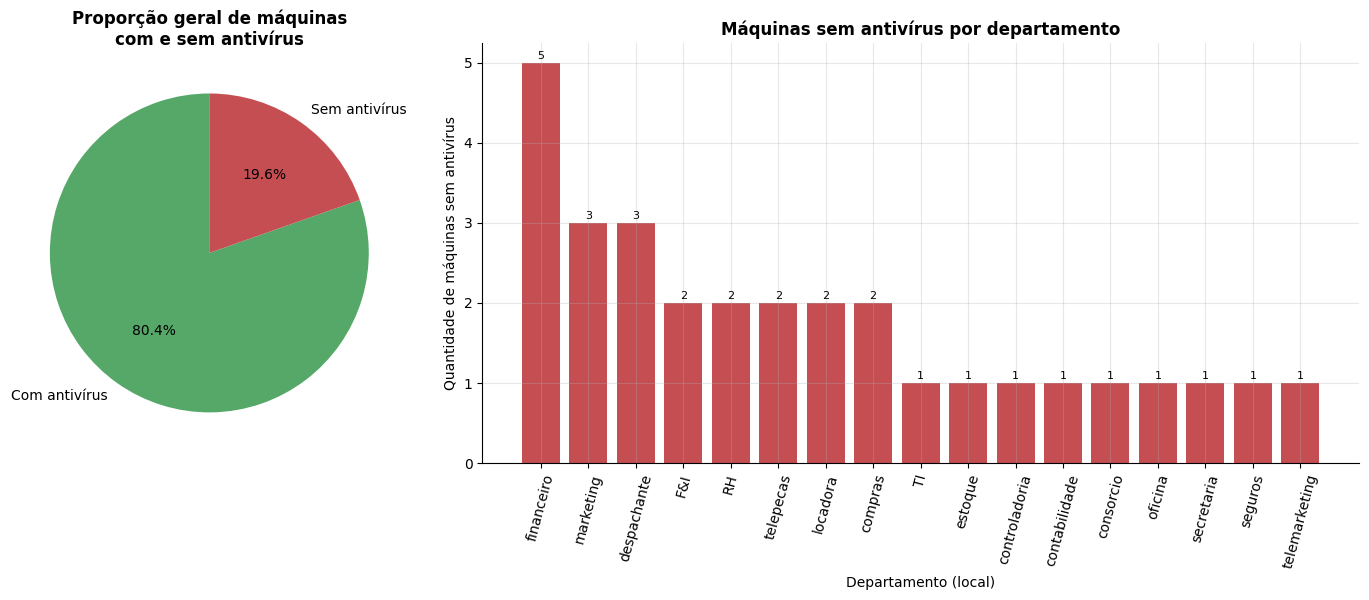

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={'width_ratios': [1, 2.2]})

# Gráfico 1: total geral (com x antivírus) em pizza
contagem_av = df_clean['anti_virus'].value_counts()
labels_av = ['Com antivírus' if l == 'sim' else 'Sem antivírus' for l in contagem_av.index]
axes[0].pie(contagem_av.values, labels=labels_av, autopct='%1.1f%%', startangle=90,
            colors=['#55A868', '#C44E52'])
axes[0].set_title('Proporção geral de máquinas\ncom e sem antivírus', fontweight='bold')

# Gráfico 2: sem antivírus por departamento
axes[1].bar(sem_av_por_departamento.index, sem_av_por_departamento.values, color='#C44E52')
axes[1].set_title('Máquinas sem antivírus por departamento', fontweight='bold')
axes[1].set_xlabel('Departamento (local)')
axes[1].set_ylabel('Quantidade de máquinas sem antivírus')
axes[1].tick_params(axis='x', rotation=75)
axes[1].yaxis.set_major_locator(mticker.MaxNLocator(integer=True))

for i, valor in enumerate(sem_av_por_departamento.values):
    axes[1].annotate(f'{int(valor)}', xy=(i, valor), xytext=(0, 3),
                      textcoords='offset points', ha='center', fontsize=8)

plt.tight_layout()
plt.show()

**Resposta:** o total de máquinas sem antivírus está no primeiro gráfico
(proporção geral) e a quebra por departamento está no gráfico da direita,
ordenado do departamento com mais para o com menos máquinas desprotegidas.

## 6. Pergunta 4 — Departamentos com mais máquinas por tipo de processador

Primeiro, a quantidade **total** de cada família de processador
(Pentium R, Celeron R, i3, i5, i7) na empresa toda. Depois, a
distribuição de cada família **por departamento**.

In [21]:
ordem_familias = ['Pentium R', 'Celeron R', 'i3', 'i5', 'i7']

total_por_familia = (
    df_clean['processador_familia']
    .value_counts()
    .reindex(ordem_familias)
    .fillna(0)
    .astype(int)
)
print(total_por_familia)

processador_familia
Pentium R    21
Celeron R     8
i3           89
i5           34
i7            1
Name: count, dtype: int64


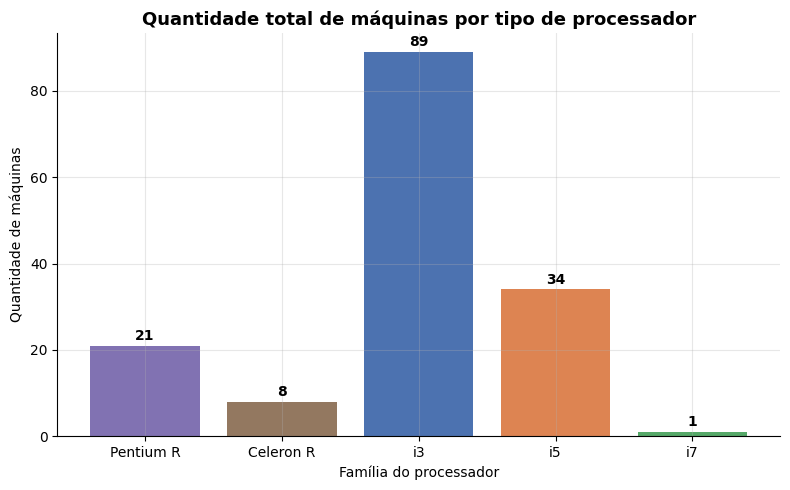

In [22]:
fig, ax = plt.subplots(figsize=(8, 5))
cores_proc = ['#8172B2', '#937860', '#4C72B0', '#DD8452', '#55A868']
barras = ax.bar(total_por_familia.index, total_por_familia.values, color=cores_proc)

ax.set_title('Quantidade total de máquinas por tipo de processador', fontsize=13, fontweight='bold')
ax.set_xlabel('Família do processador')
ax.set_ylabel('Quantidade de máquinas')

for barra in barras:
    altura = barra.get_height()
    ax.annotate(f'{int(altura)}', xy=(barra.get_x() + barra.get_width() / 2, altura),
                xytext=(0, 4), textcoords='offset points', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

In [23]:
# Tabela departamento x família de processador (contagem)
tabela_proc_departamento = (
    pd.crosstab(df_clean['local'], df_clean['processador_familia'])
    .reindex(columns=ordem_familias, fill_value=0)
)
tabela_proc_departamento

processador_familia,Pentium R,Celeron R,i3,i5,i7
local,,,,,
F&I,1,0,2,2,0
RH,0,0,3,3,0
TI,0,0,1,3,0
adm consorcio,0,0,4,0,0
caixa oficina,2,0,0,0,0
compras,1,0,2,0,0
consorcio,2,0,8,0,0
contabilidade,0,2,6,2,0
controladoria,0,1,1,1,0


In [24]:
# Departamento com MAIS máquinas de cada família de processador
print('Departamento com mais máquinas de cada tipo de processador:\n')
for familia in ordem_familias:
    coluna = tabela_proc_departamento[familia]
    if coluna.sum() == 0:
        print(f'- {familia}: nenhuma máquina encontrada')
        continue
    depto_top = coluna.idxmax()
    qtd_top = coluna.max()
    print(f'- {familia}: "{depto_top}" com {qtd_top} máquina(s)')

Departamento com mais máquinas de cada tipo de processador:

- Pentium R: "telemarketing" com 4 máquina(s)
- Celeron R: "contabilidade" com 2 máquina(s)
- i3: "novos" com 12 máquina(s)
- i5: "oficina" com 6 máquina(s)
- i7: "marketing" com 1 máquina(s)


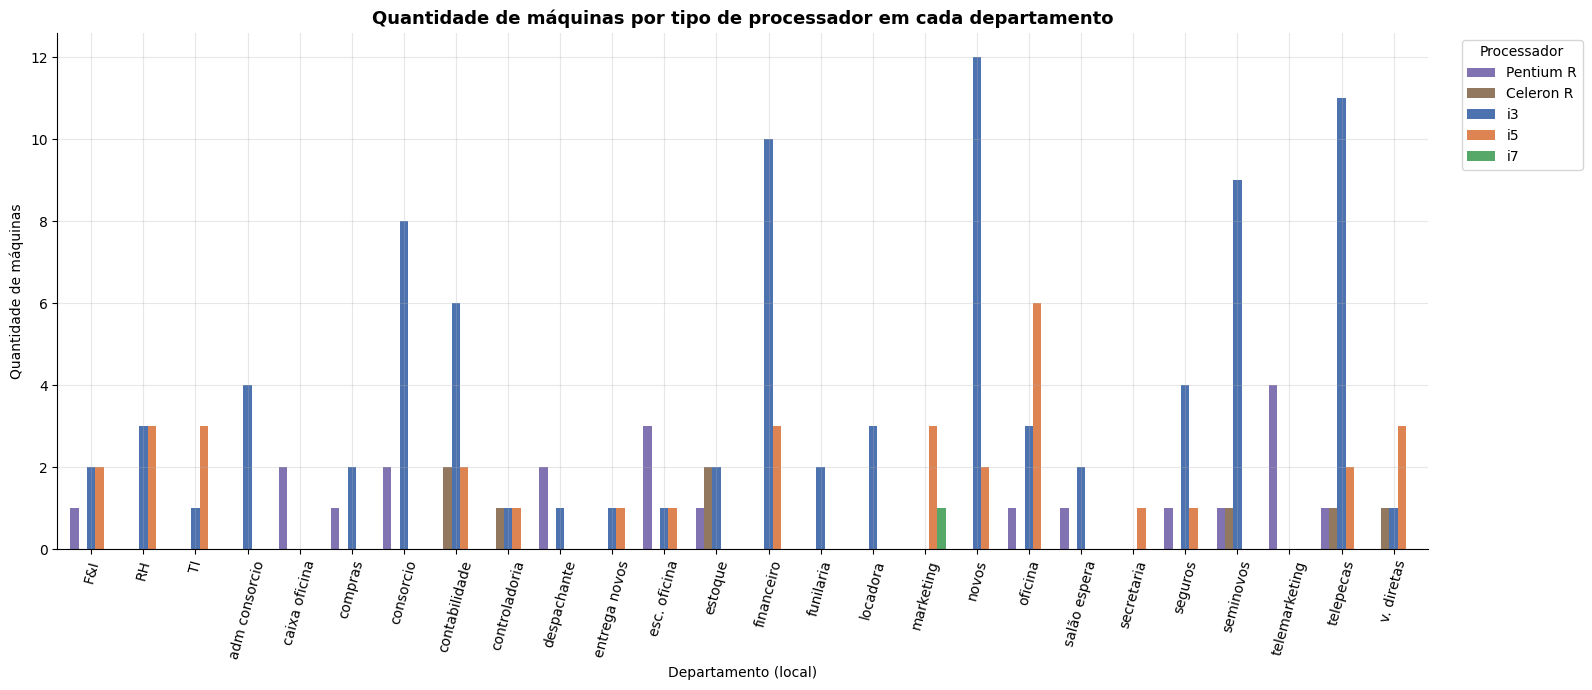

In [25]:
# Gráfico de barras agrupadas: quantidade de cada processador por departamento
fig, ax = plt.subplots(figsize=(16, 7))
tabela_proc_departamento.plot(kind='bar', ax=ax, color=cores_proc, width=0.8)

ax.set_title('Quantidade de máquinas por tipo de processador em cada departamento',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Departamento (local)')
ax.set_ylabel('Quantidade de máquinas')
ax.legend(title='Processador', bbox_to_anchor=(1.02, 1), loc='upper left')
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

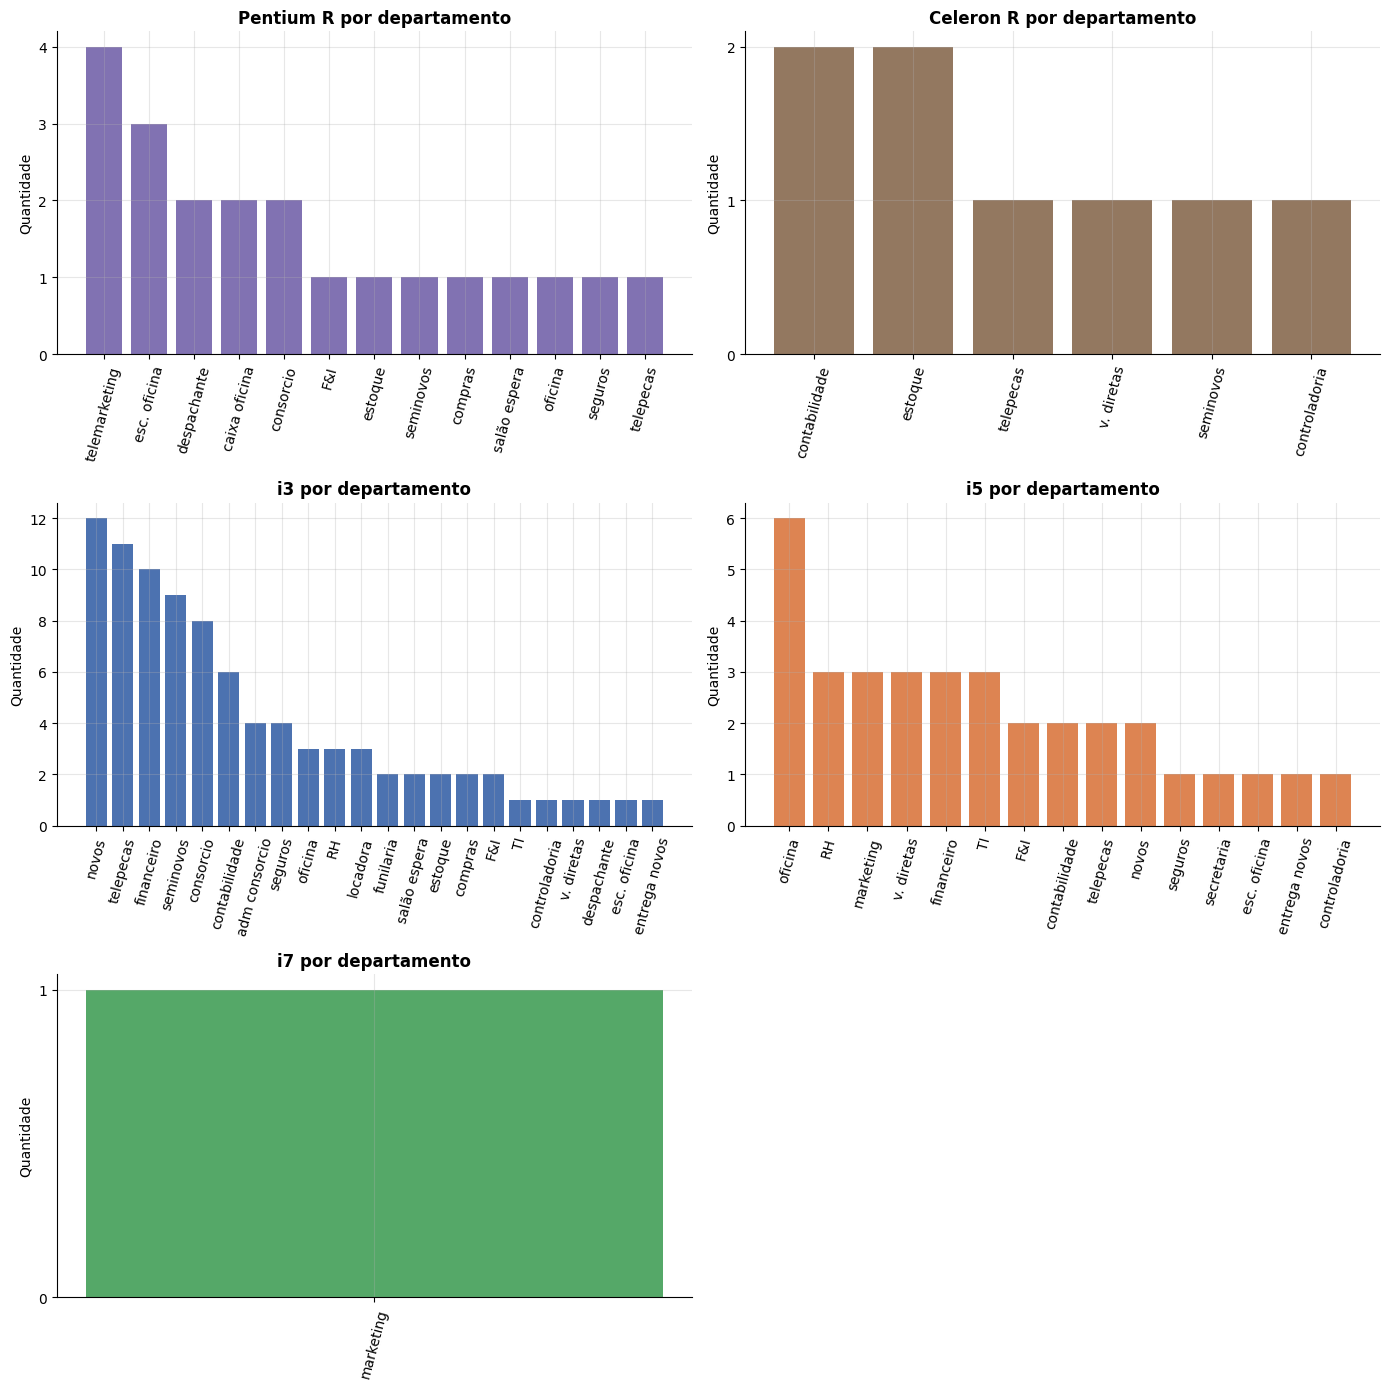

In [26]:
# Gráfico complementar: para cada família de processador, ranking dos departamentos que mais possuem
fig, axes = plt.subplots(3, 2, figsize=(14, 14))
axes = axes.flatten()

for i, familia in enumerate(ordem_familias):
    serie = tabela_proc_departamento[familia].sort_values(ascending=False)
    serie = serie[serie > 0]
    axes[i].bar(serie.index, serie.values, color=cores_proc[i])
    axes[i].set_title(f'{familia} por departamento', fontweight='bold')
    axes[i].set_ylabel('Quantidade')
    axes[i].tick_params(axis='x', rotation=75)
    axes[i].yaxis.set_major_locator(mticker.MaxNLocator(integer=True))

# Remove o eixo extra (temos 5 famílias e 6 posições no grid 3x2)
fig.delaxes(axes[5])

plt.tight_layout()
plt.show()

**Resposta:** o gráfico de barras totais mostra a quantidade geral de cada
tipo de processador na empresa; a tabela cruzada e o gráfico de barras
agrupadas mostram a distribuição por departamento; e os pequenos gráficos
individuais no final destacam, para cada tipo de processador, quais
departamentos concentram mais máquinas daquele modelo (veja também a lista
impressa acima com o departamento líder de cada família).

## 7. Resumo das respostas

- **PC vs NB:** ver contagem e gráfico gerais, além da quebra por
  departamento, na seção 3.
- **Departamento com menor média de RAM por equipamento:** ver seção 4
  (departamento destacado em vermelho no gráfico de barras horizontais, com
  a quantidade de equipamentos de cada departamento indicada em cada barra).
- **Máquinas sem antivírus:** total geral e quebra por departamento na seção 5.
- **Processadores por departamento:** totais gerais, tabela cruzada e
  departamento líder de cada tipo de processador na seção 6.
